In [ ]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

folder = r'C:\MAT3300'
sm_file = os.path.join(folder, 'data_allhours_plev.nc') 

ds_sm = xr.open_dataset(sm_file)
print(ds_sm)

<xarray.Dataset> Size: 7kB
Dimensions:         (valid_time: 276, pressure_level: 1, latitude: 1,
                     longitude: 2)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 2kB 2003-01-01 ... 2025-12-01
  * pressure_level  (pressure_level) float64 8B 925.0
  * latitude        (latitude) float64 8B 40.5
  * longitude       (longitude) float64 16B -3.75 -3.0
Data variables:
    no2             (valid_time, pressure_level, latitude, longitude) float32 2kB ...
    go3             (valid_time, pressure_level, latitude, longitude) float32 2kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-20T12:39 GRIB to CDM+CF via cfgrib-0.9.1...
Nearest latitude: 40.5
Nearest longitude: -3.0
Distance from Belinchon: 49.21 k

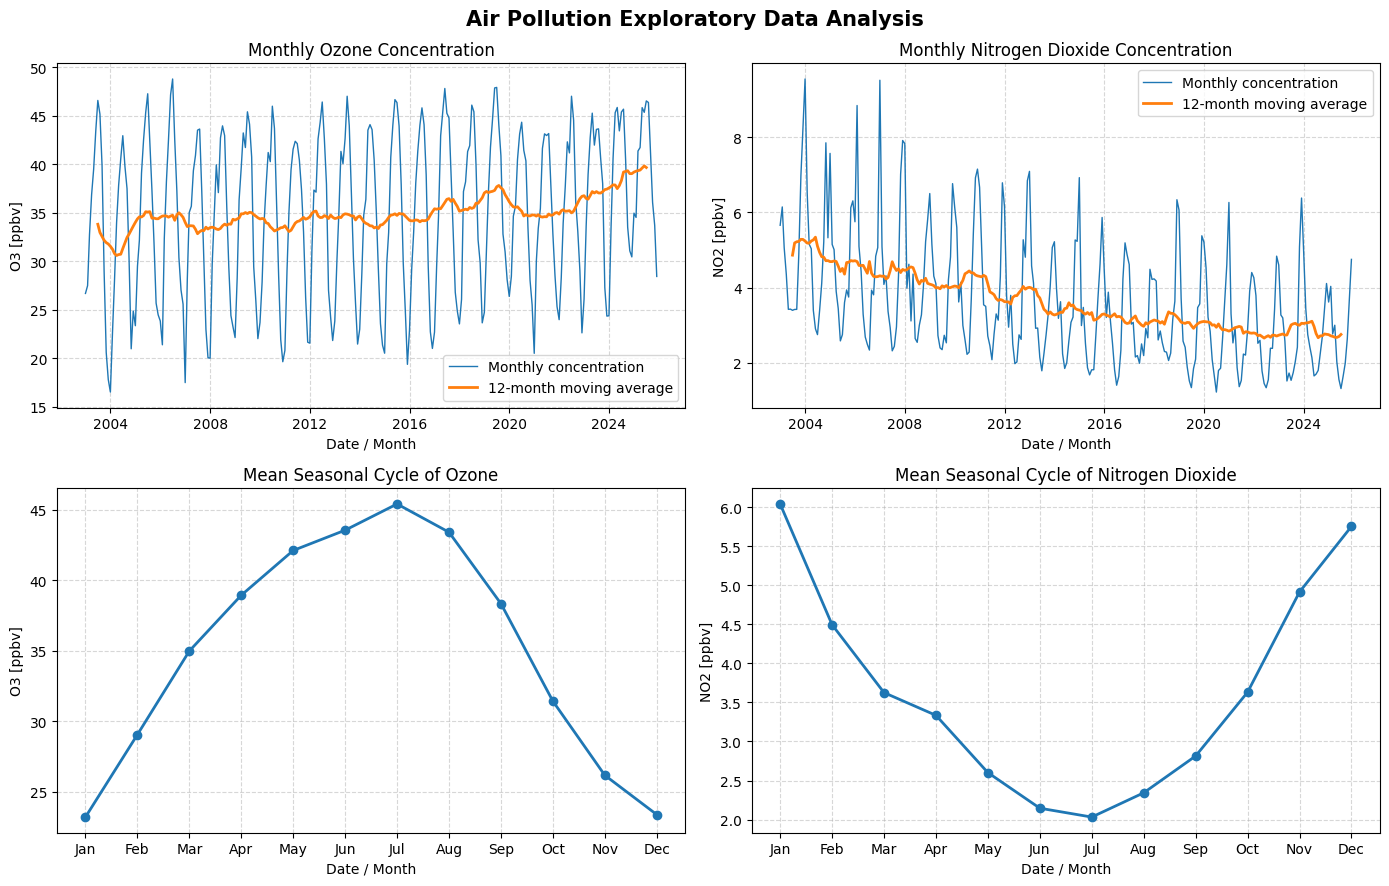


--- Annual Mean Pollution Concentrations ---
          O3    NO2
Year               
2003  33.846  4.858
2004  31.332  5.097
2005  35.095  4.511
2006  34.823  4.351
2007  32.857  4.691
2008  33.645  4.216
2009  34.945  4.048
2010  33.393  4.393
2011  34.109  3.853
2012  34.515  3.795
2013  34.875  3.579
2014  33.667  3.453
2015  34.733  3.347
2016  34.206  3.225
2017  36.410  3.006
2018  35.497  3.202
2019  37.696  2.992
2020  35.172  2.944
2021  34.597  2.954
2022  35.030  2.689
2023  37.195  3.009
2024  38.316  2.781
2025  39.694  2.748


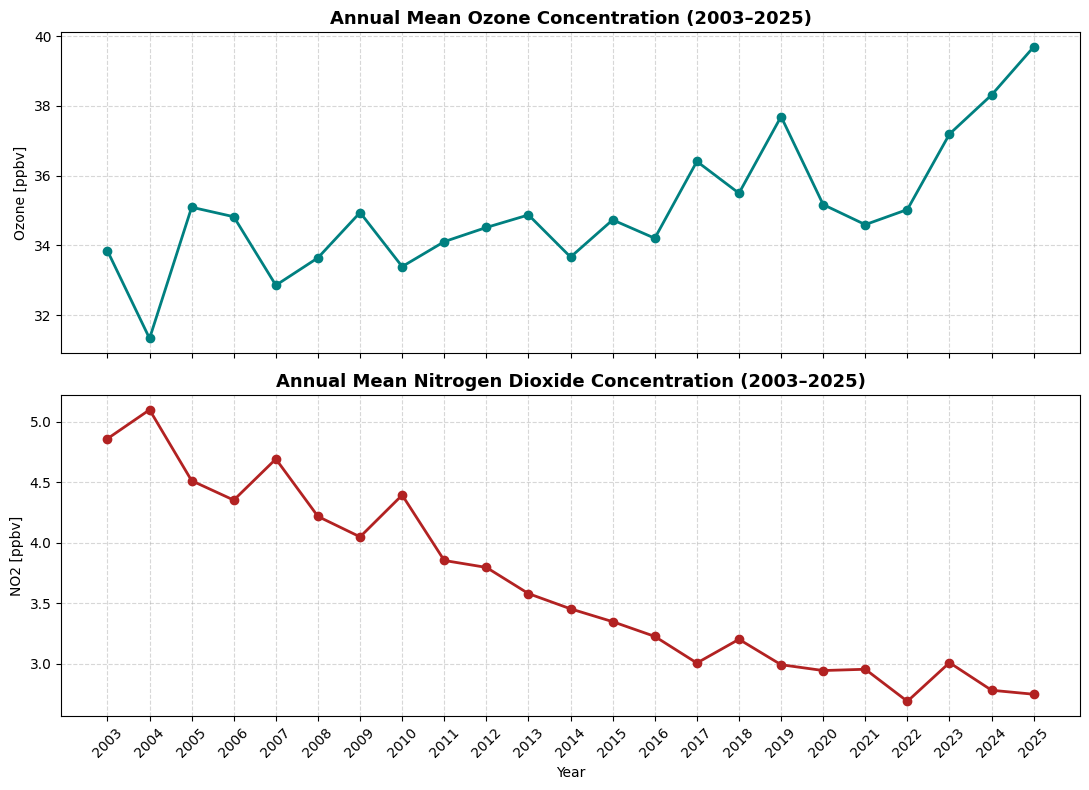

In [3]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# ==========================================================
# 1. LOAD THE POLLUTION DATASET
# ==========================================================

folder = r'C:\MAT3300'
file_path = os.path.join(folder, 'data_allhours_plev.nc')

ds = xr.open_dataset(file_path)

print(ds)

# ==========================================================
# 2. SELECT THE GRID POINT NEAREST TO BELINCHON
# ==========================================================

# Coordinates of Belinchon
target_lat = 40.0592
target_lon = -3.0510

latitudes = ds["latitude"].values
longitudes = ((ds["longitude"].values + 180) % 360) - 180

# Calculate distances using the haversine formula
lat_grid, lon_grid = np.meshgrid(
    latitudes, longitudes, indexing="ij"
)

R = 6371  # Earth radius in km

lat1 = np.radians(target_lat)
lat2 = np.radians(lat_grid)

dlat = lat2 - lat1
dlon = np.radians(lon_grid - target_lon)

a = (
    np.sin(dlat / 2)**2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin(dlon / 2)**2
)

distances = 2 * R * np.arcsin(np.sqrt(a))

lat_idx, lon_idx = np.unravel_index(
    np.argmin(distances), distances.shape
)

nearest_lat = latitudes[lat_idx]
nearest_lon = longitudes[lon_idx]
nearest_distance = distances[lat_idx, lon_idx]

print(f"Nearest latitude: {nearest_lat}")
print(f"Nearest longitude: {nearest_lon}")
print(f"Distance from Belinchon: {nearest_distance:.2f} km")

# ==========================================================
# 3. SELECT THE 925 hPa PRESSURE LEVEL
# ==========================================================

pressure_levels = ds["pressure_level"].values

pressure_idx = np.argmin(
    np.abs(pressure_levels - 925)
)

pressure_used = pressure_levels[pressure_idx]

print(f"Selected pressure level: {pressure_used} hPa")

# ==========================================================
# 4. EXTRACT OZONE AND NO2
# ==========================================================

o3 = ds["go3"].isel(
    pressure_level=pressure_idx,
    latitude=lat_idx,
    longitude=lon_idx
)

no2 = ds["no2"].isel(
    pressure_level=pressure_idx,
    latitude=lat_idx,
    longitude=lon_idx
)

# Convert mass mixing ratio (kg/kg) to approximate
# volume mixing ratio (ppbv)

M_air = 28.9647
M_O3 = 47.9982
M_NO2 = 46.0055

o3_ppbv = o3.values * (M_air / M_O3) * 1e9
no2_ppbv = no2.values * (M_air / M_NO2) * 1e9

# ==========================================================
# 5. CREATE A DATAFRAME
# ==========================================================

dates = pd.to_datetime(ds["valid_time"].values)

df = pd.DataFrame(
    {
        "O3_ppbv": o3_ppbv,
        "NO2_ppbv": no2_ppbv
    },
    index=dates
)

df.index.name = "Date"

df = df.sort_index().dropna()

print("\nFirst observations:")
print(df.head())

print("\nDescriptive statistics:")
print(df.describe())

print("\nCorrelation matrix:")
print(df.corr())

# Save extracted data
df.to_csv(
    os.path.join(folder, "pollution_concentrations.csv")
)

# ==========================================================
# 6. CALCULATE THE SEASONAL CYCLE
# ==========================================================

monthly_clim = df.groupby(
    df.index.month
).mean()

months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# ==========================================================
# 7. TIME SERIES AND SEASONAL CYCLE PLOTS
# ==========================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Ozone time series
axes[0, 0].plot(
    df.index, df["O3_ppbv"],
    linewidth=1, label="Monthly concentration"
)

axes[0, 0].plot(
    df.index,
    df["O3_ppbv"].rolling(12, center=True).mean(),
    linewidth=2, label="12-month moving average"
)

axes[0, 0].set_title("Monthly Ozone Concentration")
axes[0, 0].set_ylabel("O3 [ppbv]")
axes[0, 0].legend()

# NO2 time series
axes[0, 1].plot(
    df.index, df["NO2_ppbv"],
    linewidth=1, label="Monthly concentration"
)

axes[0, 1].plot(
    df.index,
    df["NO2_ppbv"].rolling(12, center=True).mean(),
    linewidth=2, label="12-month moving average"
)

axes[0, 1].set_title("Monthly Nitrogen Dioxide Concentration")
axes[0, 1].set_ylabel("NO2 [ppbv]")
axes[0, 1].legend()

# Ozone seasonal cycle
axes[1, 0].plot(
    range(1, 13),
    monthly_clim["O3_ppbv"],
    marker="o",
    linewidth=2
)

axes[1, 0].set_title("Mean Seasonal Cycle of Ozone")
axes[1, 0].set_ylabel("O3 [ppbv]")
axes[1, 0].set_xticks(range(1, 13))
axes[1, 0].set_xticklabels(months)

# NO2 seasonal cycle
axes[1, 1].plot(
    range(1, 13),
    monthly_clim["NO2_ppbv"],
    marker="o",
    linewidth=2
)

axes[1, 1].set_title("Mean Seasonal Cycle of Nitrogen Dioxide")
axes[1, 1].set_ylabel("NO2 [ppbv]")
axes[1, 1].set_xticks(range(1, 13))
axes[1, 1].set_xticklabels(months)

# Formatting
for ax in axes.flat:
    ax.set_xlabel("Date / Month")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle(
    "Air Pollution Exploratory Data Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(folder, "pollution_timeseries_eda.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


plt.show()

# Belinchon coordinates
target_lat = 40.0592
target_lon = -3.0510

# Handle longitude convention
if ds.longitude.max().item() > 180:
    target_lon = target_lon % 360

# Select nearest grid point and 925 hPa
data = ds.sel(
    latitude=target_lat,
    longitude=target_lon,
    pressure_level=925,
    method='nearest'
)

# ============================================================
# 2. CONVERT CONCENTRATIONS TO ppbv
# ============================================================

M_air = 28.9647
M_O3 = 47.9982
M_NO2 = 46.0055

o3_ppbv = data['go3'] * (M_air / M_O3) * 1e9
no2_ppbv = data['no2'] * (M_air / M_NO2) * 1e9

# Create DataFrame
df = pd.DataFrame(
    {
        'O3': o3_ppbv.values,
        'NO2': no2_ppbv.values
    },
    index=pd.DatetimeIndex(data.valid_time.values)
).dropna()

df = df.sort_index()

# ============================================================
# 3. CALCULATE ANNUAL MEAN CONCENTRATIONS
# ============================================================

# Weight monthly means by the number of days in each month
df['days'] = df.index.days_in_month

annual_mean = df.groupby(df.index.year).apply(
    lambda group: pd.Series({
        'O3': np.average(group['O3'], weights=group['days']),
        'NO2': np.average(group['NO2'], weights=group['days'])
    })
)

annual_mean.index.name = 'Year'

print("\n--- Annual Mean Pollution Concentrations ---")
print(annual_mean.round(3))

# Save annual results
annual_mean.to_csv(
    os.path.join(folder, 'annual_pollution_means.csv')
)

# ============================================================
# 4. PLOT ANNUAL MEAN OZONE CONCENTRATION
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(
    annual_mean.index,
    annual_mean['O3'],
    marker='o',
    linewidth=2,
    color='teal'
)

axes[0].set_title(
    'Annual Mean Ozone Concentration (2003–2025)',
    fontsize=13,
    fontweight='bold'
)

axes[0].set_ylabel('Ozone [ppbv]')
axes[0].grid(True, linestyle='--', alpha=0.5)

# ============================================================
# 5. PLOT ANNUAL MEAN NITROGEN DIOXIDE CONCENTRATION
# ============================================================

axes[1].plot(
    annual_mean.index,
    annual_mean['NO2'],
    marker='o',
    linewidth=2,
    color='firebrick'
)

axes[1].set_title(
    'Annual Mean Nitrogen Dioxide Concentration (2003–2025)',
    fontsize=13,
    fontweight='bold'
)

axes[1].set_ylabel('NO2 [ppbv]')
axes[1].set_xlabel('Year')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.xticks(annual_mean.index, rotation=45)

plt.tight_layout()

plt.savefig(
    os.path.join(folder, 'annual_pollution_concentrations.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

ds.close()


ds.close()


Selected coordinates:
Latitude: 40.5
Longitude: -3.0
Pressure level: 925.0 hPa

Pollution data:
                   O3       NO2
2003-01-01  26.676592  5.659728
2003-02-01  27.477083  6.147627
2003-03-01  32.731987  5.065744
2003-04-01  36.863903  4.355652
2003-05-01  39.500065  3.424059

FINAL OZONE MODEL: AR(2)
phi1 = 0.551208, phi2 = 0.130864
R² = 0.4032, RMSE = 2.0283 ppbv, 

OZONE: STOCHASTIC FORECAST
            Anomaly_pred  epsilon_sampled  Concentration_pred  Pollution_index
2026-01-01        0.6901          -3.0818             23.8847           0.2286
2026-02-01        1.4998           0.4577             30.5488           0.4350
2026-03-01       -2.4536          -3.3706             32.5331           0.4965
2026-04-01       -1.9322          -0.7761             37.0150           0.6353
2026-05-01        0.3589           1.7450             42.4842           0.8047
2026-06-01        2.7091           2.7641             46.2752           0.9221
2026-07-01        1.7032           0.1

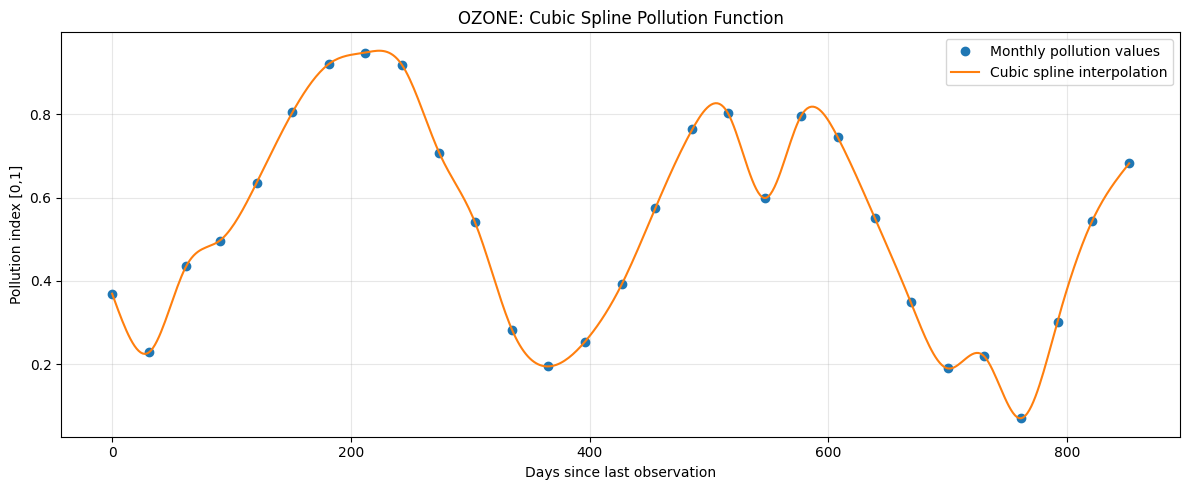


FINAL NITROGEN DIOXIDE MODEL: AR(2)
phi1 = 0.392557, phi2 = 0.359833
R² = 0.4562, RMSE = 0.7079 ppbv, 

NITROGEN DIOXIDE: STOCHASTIC FORECAST
            Anomaly_pred  epsilon_sampled  Concentration_pred  Pollution_index
2026-01-01       -0.6359           0.1806              5.4029           0.5019
2026-02-01       -1.6602          -1.0513              2.8336           0.1933
2026-03-01        0.1049           0.9855              3.7303           0.3010
2026-04-01       -0.7820          -0.2257              2.5527           0.1596
2026-05-01       -0.3518          -0.0825              2.2499           0.1232
2026-06-01       -0.3387           0.0808              1.8077           0.0701
2026-07-01       -0.3312          -0.0717              1.7017           0.0574
2026-08-01       -0.3000          -0.0481              2.0433           0.0984
2026-09-01       -0.5277          -0.2908              2.2864           0.1276
2026-10-01       -0.7832          -0.4681              2.8475      

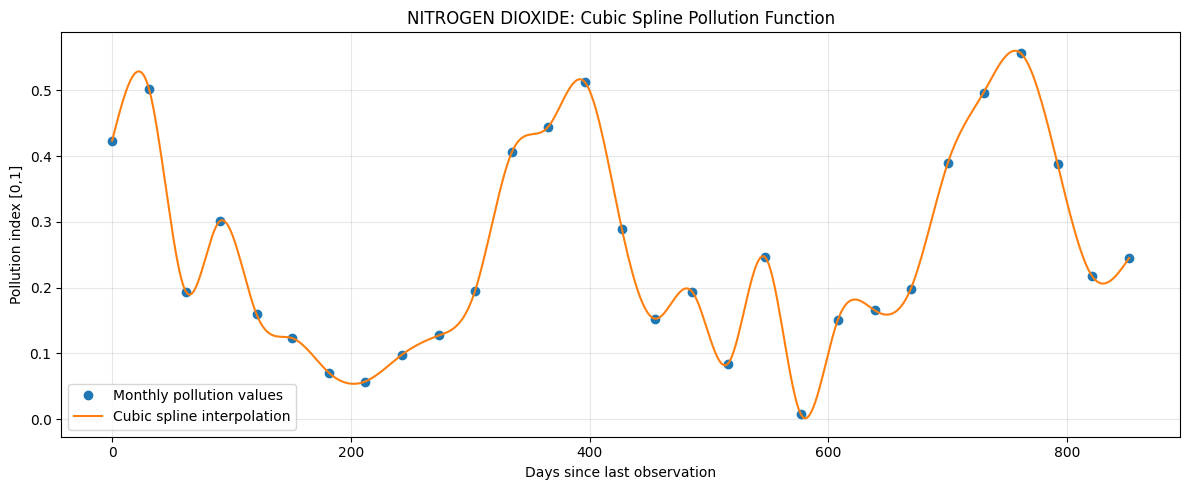

In [12]:

import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from scipy.interpolate import CubicSpline


# ============================================================
# 1. LOAD AND PREPARE POLLUTION DATA
# ============================================================

folder = r'C:\MAT3300'

file_path = os.path.join(folder, 'data_allhours_plev.nc')

ds = xr.open_dataset(file_path)

target_lat = 40.0592
target_lon = -3.0510


if float(ds.longitude.max()) > 180:
    target_lon = target_lon % 360

# Select the atmospheric data at the grid point closest to Belinchón.
# We use the 925 hPa pressure level as our selected atmospheric level.
# 'nearest' means the dataset does not need an exact coordinate match.
data = ds.sel(
    latitude=target_lat,
    longitude=target_lon,
    pressure_level=925,
    method='nearest'
)

# Print the actual coordinates selected by the dataset. These may differ slightly from our target coordinates.
print("Selected coordinates:")
print("Latitude:", float(data.latitude.values))
print("Longitude:", float(data.longitude.values))
print("Pressure level:", float(data.pressure_level.values), "hPa")


# ============================================================
# 2. CONVERT MASS MIXING RATIOS TO ppbv
# ============================================================

# Molecular masses in g/mol.
M_air = 28.9647
M_O3 = 47.9982
M_NO2 = 46.0055

# The original variables go3 and no2 are mass mixing ratios (kg/kg).
# Convert them into volume mixing ratios expressed in ppbv.
#
# Formula:
# ppbv = mass mixing ratio * (M_air / M_pollutant) * 10^9
#
# We perform this conversion separately for ozone and nitrogen dioxide.
o3_ppbv = data['go3'] * (M_air / M_O3) * 1e9
no2_ppbv = data['no2'] * (M_air / M_NO2) * 1e9

# Create a Pandas DataFrame containing the two pollutant time series.
# Each row represents an observation date.
# The index stores the corresponding dates.
df_pollution = pd.DataFrame(
    {
        'O3': o3_ppbv.values,
        'NO2': no2_ppbv.values
    },
    index=pd.DatetimeIndex(data.valid_time.values)
)

# Sort observations chronologically and remove missing values.
df_pollution = (
    df_pollution
    .sort_index()
    .dropna()
)

# Display the first observations to check that the data loaded correctly.
print("\nPollution data:")
print(df_pollution.head())




# ============================================================
# 3. FIT AR(2) AND GENERATE STOCHASTIC FORECAST
# ============================================================

def fit_AR2_forecast(
    series,
    variable,
    forecast_horizon=28,
    seed=42,
    resample_rule="MS",
):

    # Remove missing values and sort observations by date.
    s = series.dropna().sort_index()

    # If multiple observations have the same date,
    # replace them with their average.
    s = s.groupby(level=0).mean()

    # Convert the original observations to monthly averages.
    # "MS" means month start: each observation is labelled
    # with the first day of its month.
    if resample_rule is not None:
        s = s.resample(resample_rule).mean().dropna()

    # --------------------------------------------------------
    # 3.1 CALCULATE MONTHLY CLIMATOLOGY AND ANOMALIES
    # --------------------------------------------------------

    # Calculate the average concentration for each calendar month.
    # For example, all January values are averaged together,
    # all February values are averaged together, etc.
    #
    # This gives us the typical seasonal pollution pattern.
    monthly_means = (
        s.groupby(s.index.month)
        .mean()
        .reindex(range(1, 13))
        .fillna(s.mean())
    )

    # Calculate anomalies by subtracting the typical monthly
    # concentration from each observation.
    #
    # Positive anomaly = concentration above its monthly average.
    # Negative anomaly = concentration below its monthly average.
    anomalies = s - pd.Series(
        s.index.month,
        index=s.index
    ).map(monthly_means)

    # Create a DataFrame to store the anomalies and their lagged values.
    df_model = pd.DataFrame(
        {"anomaly": anomalies},
        index=s.index
    )

    # lag1 = anomaly from the previous month.
    # lag2 = anomaly from two months earlier.
    #
    # These two previous values are used to predict the next anomaly.
    df_model["lag1"] = df_model["anomaly"].shift(1)
    df_model["lag2"] = df_model["anomaly"].shift(2)

    # The first two rows do not have two previous observations.
    # Remove these incomplete rows before fitting the model.
    df_model = df_model.dropna().copy()

    # X contains the two explanatory variables: lag1 and lag2.
    X = df_model[["lag1", "lag2"]]

    # y contains the anomalies that we want the model to predict.
    y = df_model["anomaly"]

    # --------------------------------------------------------
    # 3.2 FIT THE AR(2) MODEL
    # --------------------------------------------------------

    # Fit 
    reg = LinearRegression(fit_intercept=False)

    # Estimate the two AR(2) coefficients using all observations.
    reg.fit(X, y)

    # Calculate the anomalies predicted by the fitted model.
    df_model["pred"] = reg.predict(X)

    # Calculate historical residuals:
    # residual = observed anomaly - predicted anomaly.

    df_model["epsilon"] = (
        df_model["anomaly"] - df_model["pred"]
    )

    # Store the historical residuals as a NumPy array.
    # We will randomly sample from this array when forecasting.
    residuals = df_model["epsilon"].to_numpy()

    # Extract the two estimated AR(2) coefficients.
    phi1, phi2 = reg.coef_

    # --------------------------------------------------------
    # 3.3 EVALUATE MODEL PERFORMANCE
    # --------------------------------------------------------

    # R² measures the proportion of historical anomaly variation
    # explained by the fitted AR(2) model.
    r2 = r2_score(y, df_model["pred"])

    # RMSE measures the typical magnitude of prediction errors.
    # Its unit is ppbv because the anomalies are measured in ppbv.
    rmse = float(
        np.sqrt(mean_squared_error(y, df_model["pred"]))
    )

  
    # Print the estimated coefficients and model performance.
    print(
        f"\n{'=' * 55}\n"
        f"FINAL {variable} MODEL: AR(2)\n"
        f"{'=' * 55}"
    )

    print(f"phi1 = {phi1:.6f}, phi2 = {phi2:.6f}")
    print(
        f"R² = {r2:.4f}, "
        f"RMSE = {rmse:.4f} ppbv, "
    )

    # --------------------------------------------------------
    # 3.4 GENERATE STOCHASTIC FUTURE FORECAST
    # --------------------------------------------------------

    # Create a random number generator.
    # A fixed seed makes the stochastic forecast reproducible.
    rng = np.random.default_rng(seed)

    # Calculate the minimum and maximum historical concentrations.
    # These values will be used later to normalise pollution.
    c_min = float(s.min())
    c_max = float(s.max())

    # Check that the concentration data actually vary.
    if c_max <= c_min:
        raise ValueError(
            f"{variable}: concentration has no variation."
        )

    # Generate the dates for the future monthly forecast.
    # The forecast begins in the month following the last observation.
    forecast_dates = pd.date_range(
        start=s.index[-1] + pd.offsets.MonthBegin(1),
        periods=forecast_horizon,
        freq="MS",
    )

    # Store the final two historical anomalies.
    # These are the starting values for the recursive AR(2) forecast.
    prev_anom = list(
        anomalies.iloc[-2:].to_numpy(dtype=float)
    )

    # Create empty lists to store the forecast results.
    pred_anom = []
    pred_conc = []
    pred_idx = []
    sampled_eps = []

    # Predict one month at a time.
    for dt in forecast_dates:

        # Randomly select one historical residual.
        # This introduces stochastic variation into the forecast.
        eps_next = float(rng.choice(residuals))

        # Apply the AR(2) equation:
        #
        # Next anomaly = phi1 * latest anomaly
        #              + phi2 * previous anomaly
        #              + random stochastic shock.
        anom_next = float(
            phi1 * prev_anom[-1]
            + phi2 * prev_anom[-2]
            + eps_next
        )

        # Reconstruct the pollutant concentration by adding
        # the predicted anomaly to the typical average
        # for the corresponding calendar month.
        conc_next = max(
            0.0,
            float(monthly_means.loc[dt.month]) + anom_next
        )

        # Normalise the predicted concentration to the interval [0,1].
        #
        # 0 = at or below the historical minimum.
        # 1 = at or above the historical maximum.
        # Values in between represent relative pollution intensity.
        #
        # The resulting index is dimensionless.
        p_idx = float(
            np.clip(
                (conc_next - c_min) / (c_max - c_min),
                0.0,
                1.0
            )
        )

        # Save the predicted values.
        pred_anom.append(anom_next)
        pred_conc.append(conc_next)
        pred_idx.append(p_idx)
        sampled_eps.append(eps_next)

        # Update the anomaly history.
        # The new prediction becomes the latest value
        # for calculating the following month's anomaly.
        prev_anom.append(anom_next)

    # --------------------------------------------------------
    # 3.5 ORGANISE THE FORECAST RESULTS
    # --------------------------------------------------------

    # Store all predicted values in a DataFrame.
    df_forecast = pd.DataFrame(
        {
            "Anomaly_pred": pred_anom,
            "epsilon_sampled": sampled_eps,
            "Concentration_pred": pred_conc,
            "Pollution_index": pred_idx,
        },
        index=forecast_dates,
    )

    # Display the forecast results.
    print(f"\n{variable}: STOCHASTIC FORECAST")
    print(df_forecast.round(4))

    # --------------------------------------------------------
    # 3.6 CALCULATE HISTORICAL POLLUTION INDEX
    # --------------------------------------------------------

    # Apply the same normalisation formula to historical concentrations.
    # This allows historical and forecast pollution indices
    # to be compared on the same dimensionless scale.
    hist_idx = np.clip(
        (s - c_min) / (c_max - c_min),
        0.0,
        1.0
    )

    # --------------------------------------------------------
    # 3.7 INTERPOLATE THE POLLUTION INDEX USING CUBIC SPLINES
    # --------------------------------------------------------

    # Add the last historical date before the forecast dates.
    # This ensures that the continuous function starts
    # at the final observed pollution index.
    interp_dates = (
        pd.DatetimeIndex([s.index[-1]])
        .append(forecast_dates)
    )

    # Combine the last observed index with all future
    # monthly predicted pollution indices.
    interp_vals = np.concatenate(
        (
            [float(hist_idx.iloc[-1])],
            df_forecast["Pollution_index"].to_numpy()
        )
    )

    # Convert calendar dates into numerical time values.
    # t = 0 corresponds to the last historical observation.
    # All subsequent values are measured in days.
    t_days = (
        interp_dates - s.index[-1]
    ).days.to_numpy(dtype=float)

    # Construct a cubic spline 
    cs = CubicSpline(
        t_days,
        interp_vals,
        bc_type="natural",
        extrapolate=True
    )

    # Input: time in days since the final historical observation.
    # Output: dimensionless pollution index between 0 and 1.
    #
    # np.clip prevents the spline from producing values
    # outside the required [0,1] interval.
    def pollution_function(t):

        # Convert the input into a NumPy array.
        # This allows the function to accept either a single
        # time value or multiple time values.
        t_arr = np.asarray(t, dtype=float)

        # Evaluate the cubic spline and enforce the [0,1] bounds.
        out = np.clip(cs(t_arr), 0.0, 1.0)

        # Return a regular float for a single input,
        # or an array when multiple time values are supplied.
        return float(out) if np.ndim(t) == 0 else out

    # --------------------------------------------------------
    # 3.8 PLOT THE CONTINUOUS POLLUTION FUNCTION
    # --------------------------------------------------------


    t_smooth = np.linspace(
        t_days[0],
        t_days[-1],
        500
    )

    # Plot the original monthly pollution values as points
    # and the continuous cubic spline as a curve.
    plt.figure(figsize=(12, 5))

    plt.plot(
        t_days,
        interp_vals,
        'o',
        label='Monthly pollution values'
    )

    plt.plot(
        t_smooth,
        pollution_function(t_smooth),
        label='Cubic spline interpolation'
    )

    plt.xlabel('Days since last observation')
    plt.ylabel('Pollution index [0,1]')
    plt.title(f'{variable}: Cubic Spline Pollution Function')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

  
    return {
        "coefficients": reg.coef_,
        "r2": r2,
        "rmse": rmse,
        "historical_model": df_model,
        "forecast": df_forecast,
        "pollution_function": pollution_function,
        "t_days": t_days,
        "interpolation_values": interp_vals,
    }



# Set the number of months to forecast into the future.
forecast_horizon = 28#we check

# Fit the AR(2) model to ozone concentrations.
# The seed ensures that this stochastic forecast is reproducible.
O3_results = fit_AR2_forecast(
    df_pollution['O3'],
    'OZONE',
    forecast_horizon=forecast_horizon,
    seed=42
)

# Fit the same AR(2) procedure to nitrogen dioxide concentrations.
# A different seed gives NO2 an independent sequence of random shocks.
NO2_results = fit_AR2_forecast(
    df_pollution['NO2'],
    'NITROGEN DIOXIDE',
    forecast_horizon=forecast_horizon,
    seed=43
)


P_O3 = O3_results['pollution_function']
P_NO2 = NO2_results['pollution_function']



In [ ]:
a=0.5
b=0.5 #subject to change in our sensitivity analysis
def final_pollution(t,a,b):
    return a*P_O3(t)+b*P_NO2(t)
print(final_pollution(232))

0.6963385686210037


Here we define the pollution function as the weighted sum of the two variables. We can change the coefficients according to our scenario. Usually, ozone pollution is more detrimental for plants.

In [ ]:
c=[1,2,3,4,5,6]# some sensitivity coefficient that will be calibrated manually
#Final function for our model
a=0.5
b-0.5
def final_pollution_lv(t,a,b,i):
    return 1-c[i]*final_pollution(t,a,b)

In [ ]:
import numpy as np
#habitat reduction
a=0.5#a<1/2 to indicate slow continuous decay of land
def habitat_reduction(t,a):
    return 1/(t+1)**a
#if we want more interesting, sudden habitat reduction and then small increase, then habitat reduction etc
def habitat_reduction_t(t):
    return np.sin(t)/t


np.float64(0.5791384819626655)